In [10]:
import numpy as np
import ifcopenshell
import heapq
import matplotlib.pyplot as plt

# for some reason ifcopenshell.api is not imported when importing ifcopenshell, so we need to import it explicitly
import ifcopenshell.api.root
import ifcopenshell.api.unit
import ifcopenshell.api.context
import ifcopenshell.api.project
import ifcopenshell.api.geometry

model = ifcopenshell.open("Function_Model_hospital.ifc")

# defined as a dictionary, because there can be multiple boundaries related by openings
def get_boundary_room(space):
    b_room = {}
    for boundary in space.BoundedBy:
        corr_boundary = boundary.CorrespondingBoundary
        b_room[boundary.RelatedBuildingElement.Name] = corr_boundary.RelatingSpace
    return b_room

def get_openings(space):
    openings = {}
    for boundary in space.BoundedBy:
        if boundary.RelatedBuildingElement.is_a("IfcOpeningElement"):
            openings[boundary.RelatedBuildingElement.Name] = boundary.RelatedBuildingElement
    return openings

def get_coordinates(entity):
    matrix = ifcopenshell.util.placement.get_local_placement(entity.ObjectPlacement)
    return matrix[:,3][0:3]

###### other functions to add later:
# get length/width of a space
# calculate distance between spaces




In [80]:
import networkx as nx
import plotly.graph_objects as go

def build_nx_space_graph(model):
    """Build a graph of IfcSpaces connected through IfcOpeningElements."""
    G = nx.Graph()

    for space in model.by_type("IfcSpace"):
        s1 = space.Name or f"IfcSpace_{space.id()}"
        G.add_node(s1, ifc_id=space.id())

        for b in getattr(space, "BoundedBy", []):
            if not b.is_a("IfcRelSpaceBoundary2ndLevel"):
                continue

            cb = getattr(b, "CorrespondingBoundary", None)
            if not cb:
                continue

            elem = getattr(b, "RelatedBuildingElement", None)
            if not elem or not elem.is_a("IfcOpeningElement"):
                continue

            s2_obj = cb.RelatingSpace
            s2 = s2_obj.Name or f"IfcSpace_{s2_obj.id()}"
            opening_name = elem.Name or f"IfcOpeningElement_{elem.id()}"

            if not G.has_edge(s1, s2):
                G.add_edge(
                    s1,
                    s2,
                    opening=opening_name,
                    opening_id=elem.id(),
                    boundary_id=b.id(),
                    corresponding_boundary_id=cb.id(),
                )

    return G

G = build_nx_space_graph(model)

In [12]:
# Keep the relationship spaces and boundary spaces separate.
graph_space_by_node = {
    space.Name or f"IfcSpace_{space.id()}": space
    for space in model.by_type("IfcSpace")
    if not getattr(space, "BoundedBy", [])
}

boundary_space_by_node = {
    space.Name or f"IfcSpace_{space.id()}": space
    for space in model.by_type("IfcSpace")
    if getattr(space, "BoundedBy", [])
}

In [118]:
import heapq
import networkx as nx
import ifcopenshell.geom
from shapely.geometry import MultiPoint

# Map graph nodes to the duplicate spaces containing boundary relationships.
space_by_node = boundary_space_by_node


def node_coordinates(node):
    """Return the x, y coordinates for a graph node."""
    return get_coordinates(space_by_node[node])[:2]


geometry_settings = ifcopenshell.geom.settings()


def get_space_wall_footprints(node):
    """Return 2D wall footprints forming the space boundary."""
    space = space_by_node[node]
    walls = []

    for boundary in getattr(space, "BoundedBy", []):
        wall = getattr(boundary, "RelatedBuildingElement", None)
        if wall is not None and wall.is_a("IfcWall"):
            walls.append(wall)

    if not walls:
        wall_prefix = f"{node}wall".lower()
        walls = [
            wall
            for wall in model.by_type("IfcWall")
            if (wall.Name or "").lower().startswith(wall_prefix)
        ]

    wall_footprints = []
    for wall in walls:
        try:
            shape = ifcopenshell.geom.create_shape(geometry_settings, wall)
        except RuntimeError:
            continue

        vertices = np.asarray(shape.geometry.verts).reshape(-1, 3)
        transform = np.asarray(shape.transformation.matrix).reshape(4, 4)
        homogeneous_vertices = np.column_stack(
            (vertices, np.ones(len(vertices)))
        )
        world_vertices = (homogeneous_vertices @ transform)[:, :3]
        footprint = MultiPoint(world_vertices[:, :2]).convex_hull
        if not footprint.is_empty:
            wall_footprints.append(footprint)

    return wall_footprints


def furthest_coordinates_from_opening(node, opening):
    """Return the wall point farthest from the edge opening."""
    opening_coordinates = get_coordinates(opening)[:2]
    wall_footprints = get_space_wall_footprints(node)

    if wall_footprints:
        candidate_points = np.vstack([
            np.asarray(footprint.exterior.coords)
            for footprint in wall_footprints
        ])
        distances = np.linalg.norm(
            candidate_points - opening_coordinates,
            axis=1,
        )
        return candidate_points[np.argmax(distances)]

    space_coordinates = node_coordinates(node)
    direction_away_from_opening = space_coordinates - opening_coordinates
    return space_coordinates + direction_away_from_opening


def edge_cost(graph, current, neighbor, start=None, entry_opening=None):
    """Measure from the current position to the next opening."""
    opening_id = graph.edges[current, neighbor].get("opening_id")
    if opening_id is None:
        return float(np.linalg.norm(
            node_coordinates(current) - node_coordinates(neighbor)
        ))

    opening = model.by_id(opening_id)
    if current == start:
        current_coordinates = furthest_coordinates_from_opening(
            current,
            opening,
        )
    elif entry_opening is not None:
        current_coordinates = get_coordinates(entry_opening)[:2]
    else:
        current_coordinates = node_coordinates(current)

    return float(np.linalg.norm(
        current_coordinates - get_coordinates(opening)[:2]
    ))


def final_exit_cost(graph, previous, goal, exit_opening_name=None):
    """Return the distance across the goal space to its exit opening."""
    entering_opening_id = graph.edges[previous, goal].get("opening_id")

    if exit_opening_name is not None:
        exit_openings = [
            opening
            for opening in model.by_type("IfcOpeningElement")
            if opening.Name == exit_opening_name
        ]
    else:
        goal_space = space_by_node[goal]
        goal_openings = [
            boundary.RelatedBuildingElement
            for boundary in getattr(goal_space, "BoundedBy", [])
            if (
                boundary.is_a("IfcRelSpaceBoundary2ndLevel")
                and getattr(boundary, "RelatedBuildingElement", None)
                and boundary.RelatedBuildingElement.is_a("IfcOpeningElement")
            )
        ]
        exit_openings = [
            opening
            for opening in goal_openings
            if opening.id() != entering_opening_id
        ]

    if len(exit_openings) != 1:
        raise ValueError(
            f"Expected one exit opening for {goal!r}; "
            "pass exit_opening_name to a_star when it is not a second "
            "opening in the goal space"
        )

    entering_coordinates = get_coordinates(
        model.by_id(entering_opening_id)
    )[:2]
    exit_coordinates = get_coordinates(exit_openings[0])[:2]
    return float(np.linalg.norm(entering_coordinates - exit_coordinates))


def h_n(current, goal):
    """Euclidean heuristic."""
    return float(np.linalg.norm(
        node_coordinates(current) - node_coordinates(goal)
    ))


def a_star(graph, start, goal, exit_opening_name=None):
    """Find the shortest path and include the goal-room exit distance."""
    if start not in graph:
        raise ValueError(f"Unknown start node: {start}")

    if goal not in graph:
        raise ValueError(f"Unknown goal node: {goal}")

    open_set = [(h_n(start, goal), 0.0, start)]
    g_score = {start: 0.0}
    came_from = {}

    while open_set:
        _, current_cost, current = heapq.heappop(open_set)

        if current_cost > g_score.get(current, float("inf")):
            continue

        if current == goal:
            path = [current]
            while current in came_from:
                current = came_from[current]
                path.append(current)

            path.reverse()
            distance = g_score[goal]
            if len(path) > 1:
                distance += final_exit_cost(
                    graph,
                    path[-2],
                    goal,
                    exit_opening_name=exit_opening_name,
                )
            return path, distance

        entry_opening = None
        if current != start and current in came_from:
            previous = came_from[current]
            entry_opening_id = graph.edges[previous, current].get("opening_id")
            if entry_opening_id is not None:
                entry_opening = model.by_id(entry_opening_id)

        for neighbor in graph.neighbors(current):
            cost = edge_cost(
                graph,
                current,
                neighbor,
                start=start,
                entry_opening=entry_opening,
            )
            tentative_g_score = g_score[current] + cost

            if tentative_g_score < g_score.get(neighbor, float("inf")):
                came_from[neighbor] = current
                g_score[neighbor] = tentative_g_score
                f_score = tentative_g_score + h_n(neighbor, goal)
                heapq.heappush(
                    open_set,
                    (f_score, tentative_g_score, neighbor)
                )

    raise nx.NetworkXNoPath(
        f"No path exists between {start!r} and {goal!r}"
    )


In [108]:
def draw_space_wall_boundary(node):
    """Draw the 2D footprints of walls bounding a space."""
    fig, axis = plt.subplots()

    for footprint in get_space_wall_footprints(node):
        x_values, y_values = footprint.exterior.xy
        axis.plot(x_values, y_values, "k-")

    axis.set_aspect("equal")
    axis.set_title(f"Wall boundary: {node}")
    axis.set_xlabel("X")
    axis.set_ylabel("Y")
    plt.show()


['OR2', 'AB2', 'ExB2', 'Setup1', 'SW_Circ', 'OR1', 'Set_Corr', 'ExB1', 'AB1', 'Store1', 'NW_Circ', 'ST_Stock', 'ExB3', 'AB3', 'IT1', 'Cath_Lab', 'Scrub1', 'Hyb_Theatre', 'Ctrl1', 'Med1', 'Lab1', 'SE_Circ', 'CPU2', 'Store2', 'CPU1', 'Travel1', 'Disp1', 'Clean2', 'ST_Equip1', 'Off1', 'Off2', 'AmenitiesF', 'AmenitiesM', 'LiftLobby1', 'LiftLobby2', 'WC', 'Lift_Circ', 'NE_Circ', 'Wait', 'Travel2', 'Int1', 'Int2', 'Int3', 'Int4', 'Cons1', 'Copy1', 'Change_Corr', 'Lounge', 'RecBay_Circ3', 'ST_Gen', 'Meet1', 'Stair_Circ', 'StaffR', 'ExB4', 'AnBay1', 'Setup2', 'BayCirc1', 'ST_Equip2', 'ST_Equip3', 'Bay_Res', 'OR3', 'Clean1', 'Dirty1', 'RecBay_Circ1', 'Clean3', 'Dirty2', 'RecBay_Circ2', 'ACC1', 'Plant']


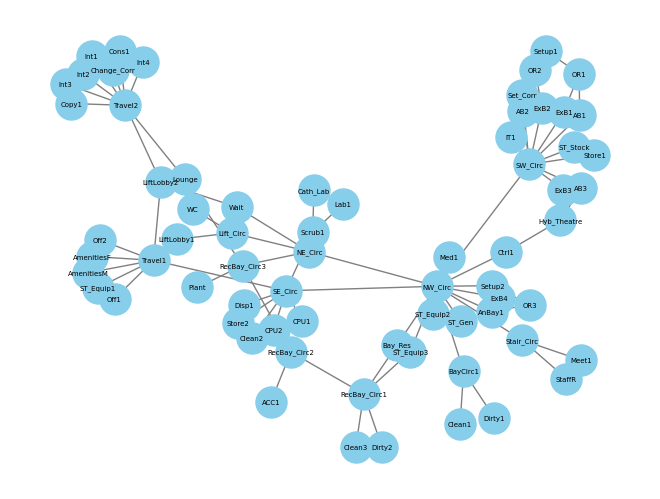

In [107]:
print(G.nodes)

goal = list(G.nodes)[-1]

# print(goal)

# use this to visualise/debug the graph
nx.draw(G, with_labels=True, node_size=500, node_color='skyblue', font_size=5, font_color='black', edge_color='gray')
plt.show()


Putting it all together for the current model...

In [25]:
# For each room, calculate A* to each goal, then store the shortest cost (i.e. either goal1, goal2, or goal3)
# then identify the 3 longest travel distance cases

goal1 = "Stair_Circ" # exit name = "north_exit"
goal2 = "RecBay_Circ2" # exit name = "south_exit"
goal3 = "Wait" # exit name = "west_exit"

goal = [goal1, goal2, goal3]
exit_names = {
    goal1: "Stair1_Exit",
    goal2: "Stair2_Exit",
    goal3: "Stair3_Exit"
}

# the point of this is to store an array of the 3 longest travel distances, which are saved as dictionaries with the room, goal, distance and travel path
largest_travel_goal1 = []
largest_travel_goal2 = []
largest_travel_goal3 = []

for exit_goal in goal:

    print("-----------------------------------\n GOAL= ", exit_goal, "\n-----------------------------------")

    for room in list(G.nodes):
        print("Room", room)
        path, distance = a_star(G, room, exit_goal, exit_opening_name=exit_names[exit_goal])

        print("Path:", path)
        print("Distance: %.2f" % distance, "m\n")

        if exit_goal == goal1:
            if len(largest_travel_goal1) < 3:
                travel_path = {
                    "room": room,
                    "goal": exit_goal,
                    "distance": distance
                }
                largest_travel_goal1.append(travel_path)
                largest_travel_goal1 = sorted(largest_travel_goal1, key=lambda x: x["distance"], reverse=True)
            else:
                if distance > largest_travel_goal1[-1]["distance"]:
                    travel_path = {
                        "room": room,
                        "goal": exit_goal,
                        "path": path,
                        "distance": distance
                    }
                    largest_travel_goal1[-1] = travel_path
                    largest_travel_goal1 = sorted(largest_travel_goal1, key=lambda x: x["distance"], reverse=True)

        elif exit_goal == goal2:
            if len(largest_travel_goal2) < 3:
                travel_path = {
                    "room": room,
                    "goal": exit_goal,
                    "distance": distance
                }
                largest_travel_goal2.append(travel_path)
                largest_travel_goal2 = sorted(largest_travel_goal2, key=lambda x: x["distance"], reverse=True)
            else:
                if distance > largest_travel_goal2[-1]["distance"]:
                    travel_path = {
                        "room": room,
                        "goal": exit_goal,
                        "path": path,
                        "distance": distance
                    }
                    largest_travel_goal2[-1] = travel_path
                    largest_travel_goal2 = sorted(largest_travel_goal2, key=lambda x: x["distance"], reverse=True)
                    
        elif exit_goal == goal3:
            if len(largest_travel_goal3) < 3:
                travel_path = {
                    "room": room,
                    "goal": exit_goal,
                    "distance": distance
                }
                largest_travel_goal3.append(travel_path)
                largest_travel_goal3 = sorted(largest_travel_goal3, key=lambda x: x["distance"], reverse=True)
            else:
                if distance > largest_travel_goal3[-1]["distance"]:
                    travel_path = {
                        "room": room,
                        "goal": exit_goal,
                        "path": path,
                        "distance": distance
                    }
                    largest_travel_goal3[-1] = travel_path
                    largest_travel_goal3 = sorted(largest_travel_goal3, key=lambda x: x["distance"], reverse=True)

# note that there is a slight inaccuracy, when the starting room is the same as the goal room, the distance is calculated as 0.
# it should really be the distance from the furthest point of the room to the exit, but this case is not interesting for the egress analysis, so is not being rectified.


-----------------------------------
 GOAL=  Stair_Circ 
-----------------------------------
Room OR2
Path: ['OR2', 'ExB2', 'SW_Circ', 'NW_Circ', 'Stair_Circ']
Distance: 48.68 m

Room AB2
Path: ['AB2', 'SW_Circ', 'NW_Circ', 'Stair_Circ']
Distance: 42.04 m

Room ExB2
Path: ['ExB2', 'SW_Circ', 'NW_Circ', 'Stair_Circ']
Distance: 39.81 m

Room Setup1
Path: ['Setup1', 'Set_Corr', 'SW_Circ', 'NW_Circ', 'Stair_Circ']
Distance: 42.94 m

Room SW_Circ
Path: ['SW_Circ', 'NW_Circ', 'Stair_Circ']
Distance: 38.51 m

Room OR1
Path: ['OR1', 'AB1', 'SW_Circ', 'NW_Circ', 'Stair_Circ']
Distance: 34.72 m

Room Set_Corr
Path: ['Set_Corr', 'SW_Circ', 'NW_Circ', 'Stair_Circ']
Distance: 34.00 m

Room ExB1
Path: ['ExB1', 'SW_Circ', 'NW_Circ', 'Stair_Circ']
Distance: 28.17 m

Room AB1
Path: ['AB1', 'SW_Circ', 'NW_Circ', 'Stair_Circ']
Distance: 25.13 m

Room Store1
Path: ['Store1', 'SW_Circ', 'NW_Circ', 'Stair_Circ']
Distance: 30.88 m

Room NW_Circ
Path: ['NW_Circ', 'Stair_Circ']
Distance: 45.82 m

Room ST_Stock


In [26]:
# the details of the 3 longest travel distances from the algorithm can be printed as follows
for i in range(len(largest_travel_goal1)):
    print(largest_travel_goal1[i])

for i in range(len(largest_travel_goal2)):
    print(largest_travel_goal2[i])

for i in range(len(largest_travel_goal3)):
    print(largest_travel_goal3[i])


{'room': 'Plant', 'goal': 'Stair_Circ', 'path': ['Plant', 'RecBay_Circ3', 'NE_Circ', 'NW_Circ', 'Stair_Circ'], 'distance': 102.73804034023944}
{'room': 'RecBay_Circ2', 'goal': 'Stair_Circ', 'path': ['RecBay_Circ2', 'RecBay_Circ1', 'Bay_Res', 'NW_Circ', 'Stair_Circ'], 'distance': 95.91879828016712}
{'room': 'AmenitiesM', 'goal': 'Stair_Circ', 'path': ['AmenitiesM', 'Travel1', 'LiftLobby2', 'Wait', 'NE_Circ', 'NW_Circ', 'Stair_Circ'], 'distance': 94.03257559790734}
{'room': 'OR2', 'goal': 'RecBay_Circ2', 'distance': 113.78203996506709}
{'room': 'Setup1', 'goal': 'RecBay_Circ2', 'path': ['Setup1', 'Set_Corr', 'SW_Circ', 'NW_Circ', 'NE_Circ', 'RecBay_Circ3', 'RecBay_Circ2'], 'distance': 108.04441475483203}
{'room': 'AB2', 'goal': 'RecBay_Circ2', 'distance': 107.13844101564278}
{'room': 'OR2', 'goal': 'Wait', 'distance': 82.09082877501628}
{'room': 'Setup1', 'goal': 'Wait', 'path': ['Setup1', 'Set_Corr', 'SW_Circ', 'NW_Circ', 'NE_Circ', 'Wait'], 'distance': 76.35320356478123}
{'room': 'AB2'

In [42]:
degree_list = nx.degree(G)
sorted_degree_list = sorted(degree_list, key=lambda x: x[1], reverse=True)
sorted_degree_list

[('NW_Circ', 14),
 ('SW_Circ', 11),
 ('Travel2', 9),
 ('SE_Circ', 8),
 ('Travel1', 8),
 ('RecBay_Circ1', 5),
 ('NE_Circ', 4),
 ('RecBay_Circ3', 4),
 ('OR2', 3),
 ('Setup1', 3),
 ('OR1', 3),
 ('Scrub1', 3),
 ('Hyb_Theatre', 3),
 ('LiftLobby2', 3),
 ('Lift_Circ', 3),
 ('Stair_Circ', 3),
 ('BayCirc1', 3),
 ('OR3', 3),
 ('RecBay_Circ2', 3),
 ('AB2', 2),
 ('ExB2', 2),
 ('Set_Corr', 2),
 ('ExB1', 2),
 ('AB1', 2),
 ('ExB3', 2),
 ('AB3', 2),
 ('Ctrl1', 2),
 ('LiftLobby1', 2),
 ('Wait', 2),
 ('Lounge', 2),
 ('ExB4', 2),
 ('AnBay1', 2),
 ('Setup2', 2),
 ('ST_Equip3', 2),
 ('Bay_Res', 2),
 ('Store1', 1),
 ('ST_Stock', 1),
 ('IT1', 1),
 ('Cath_Lab', 1),
 ('Med1', 1),
 ('Lab1', 1),
 ('CPU2', 1),
 ('Store2', 1),
 ('CPU1', 1),
 ('Disp1', 1),
 ('Clean2', 1),
 ('ST_Equip1', 1),
 ('Off1', 1),
 ('Off2', 1),
 ('AmenitiesF', 1),
 ('AmenitiesM', 1),
 ('WC', 1),
 ('Int1', 1),
 ('Int2', 1),
 ('Int3', 1),
 ('Int4', 1),
 ('Cons1', 1),
 ('Copy1', 1),
 ('Change_Corr', 1),
 ('ST_Gen', 1),
 ('Meet1', 1),
 ('StaffR'

In [37]:
# can use this
# print(nx.degree(G))

# print(nx.degree_histogram(G))

# (nx.degree_centrality(G))
# nx.betweenness_centrality(G)


# nx.closeness_centrality(G)

betweenness_list = nx.betweenness_centrality(G)
sorted_betweenness_list = sorted(betweenness_list.items(), key=lambda x: x[1], reverse=True)
sorted_betweenness_list


[('NW_Circ', 0.7056189640035117),
 ('SE_Circ', 0.3705882352941179),
 ('SW_Circ', 0.33896693005560435),
 ('Travel1', 0.24913666959321046),
 ('NE_Circ', 0.22540239976587656),
 ('Travel2', 0.20544337137840207),
 ('LiftLobby2', 0.1550336552531461),
 ('RecBay_Circ3', 0.13232367573895226),
 ('RecBay_Circ1', 0.0880158033362599),
 ('Lounge', 0.07060286801287678),
 ('Scrub1', 0.058384547848990345),
 ('Stair_Circ', 0.058384547848990345),
 ('BayCirc1', 0.058384547848990345),
 ('Wait', 0.053482587064676575),
 ('RecBay_Circ2', 0.04942932396839333),
 ('ST_Equip3', 0.04464442493415277),
 ('Bay_Res', 0.04464442493415277),
 ('Lift_Circ', 0.04293239683933274),
 ('Set_Corr', 0.026777875329236173),
 ('Ctrl1', 0.023266022827041263),
 ('LiftLobby1', 0.01507170032191981),
 ('AB2', 0.013681592039800993),
 ('ExB2', 0.013681592039800993),
 ('ExB1', 0.013681592039800993),
 ('AB1', 0.013681592039800993),
 ('ExB4', 0.009511267193444547),
 ('AnBay1', 0.009511267193444547),
 ('Setup2', 0.009511267193444547),
 ('ExB3

In [36]:
eigenvector_list = nx.eigenvector_centrality(G)
sorted_eigenvector_list = sorted(eigenvector_list.items(), key=lambda x: x[1], reverse=True)
sorted_eigenvector_list


[('NW_Circ', 0.5783427415083366),
 ('SW_Circ', 0.3620805080073583),
 ('SE_Circ', 0.24353586359804488),
 ('NE_Circ', 0.17405224947149883),
 ('ExB4', 0.16327339540553115),
 ('AnBay1', 0.16327339540553115),
 ('Setup2', 0.16327339540553115),
 ('ST_Equip3', 0.15819813489253864),
 ('Bay_Res', 0.15819813489253864),
 ('Ctrl1', 0.1565070341843062),
 ('Stair_Circ', 0.15309953646200597),
 ('BayCirc1', 0.15309953646200597),
 ('Med1', 0.13613402577251926),
 ('ST_Gen', 0.13613402577251926),
 ('ST_Equip2', 0.13613402577251926),
 ('OR3', 0.11529704644293232),
 ('ExB3', 0.10560057212408362),
 ('AB3', 0.10560057212408362),
 ('Travel1', 0.10516668864376172),
 ('AB2', 0.09898679491737834),
 ('ExB2', 0.09898679491737834),
 ('ExB1', 0.09898679491737834),
 ('AB1', 0.09898679491737834),
 ('Set_Corr', 0.09708365664784586),
 ('RecBay_Circ1', 0.09373543333170326),
 ('Hyb_Theatre', 0.08655253440981307),
 ('Store1', 0.08522756371229669),
 ('ST_Stock', 0.08522756371229669),
 ('IT1', 0.08522756371229669),
 ('Scrub1'

In [69]:
test = nx.degree_histogram(G)
# plt.hist(test, bins=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14], color='skyblue', edgecolor='black')
# plt.show()

# print(test)

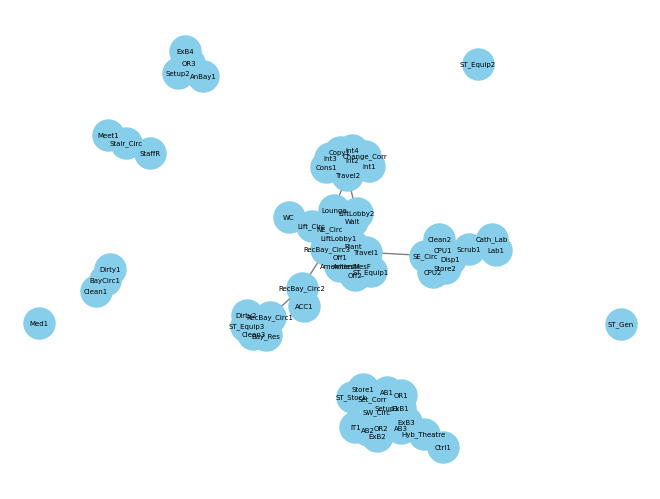

In [113]:
H = G.copy()
H.remove_node("NW_Circ")

nx.draw(H, with_labels=True, node_size=500, node_color='skyblue', font_size=5, font_color='black', edge_color='gray')
plt.show()


In [119]:
# For each room, calculate A* to each goal, then store the shortest cost (i.e. either goal1, goal2, or goal3)
# then identify the 3 longest travel distance cases

goal1 = "Stair_Circ" # exit name = "north_exit"
goal2 = "RecBay_Circ2" # exit name = "south_exit"
goal3 = "Wait" # exit name = "west_exit"

goal = [goal1, goal2, goal3]
exit_names = {
    goal1: "Stair1_Exit",
    goal2: "Stair2_Exit",
    goal3: "Stair3_Exit"
}

# the point of this is to store an array of the 3 longest travel distances, which are saved as dictionaries with the room, goal, distance and travel path
largest_travel_goal1 = []
largest_travel_goal2 = []
largest_travel_goal3 = []

for exit_goal in goal:

    print("-----------------------------------\n GOAL= ", exit_goal, "\n-----------------------------------")

    for room in list(H.nodes):
        print("Room", room)

        try:
            path, distance = a_star(H, room, exit_goal, exit_opening_name=exit_names[exit_goal])
        except nx.NetworkXNoPath:
            print(f"No path exists from {room} to {exit_goal}")
            continue

        print("Path:", path)
        print("Distance: %.2f" % distance, "m\n")

        if exit_goal == goal1:
            if len(largest_travel_goal1) < 3:
                travel_path = {
                    "room": room,
                    "goal": exit_goal,
                    "distance": distance
                }
                largest_travel_goal1.append(travel_path)
                largest_travel_goal1 = sorted(largest_travel_goal1, key=lambda x: x["distance"], reverse=True)
            else:
                if distance > largest_travel_goal1[-1]["distance"]:
                    travel_path = {
                        "room": room,
                        "goal": exit_goal,
                        "path": path,
                        "distance": distance
                    }
                    largest_travel_goal1[-1] = travel_path
                    largest_travel_goal1 = sorted(largest_travel_goal1, key=lambda x: x["distance"], reverse=True)

        elif exit_goal == goal2:
            if len(largest_travel_goal2) < 3:
                travel_path = {
                    "room": room,
                    "goal": exit_goal,
                    "distance": distance
                }
                largest_travel_goal2.append(travel_path)
                largest_travel_goal2 = sorted(largest_travel_goal2, key=lambda x: x["distance"], reverse=True)
            else:
                if distance > largest_travel_goal2[-1]["distance"]:
                    travel_path = {
                        "room": room,
                        "goal": exit_goal,
                        "path": path,
                        "distance": distance
                    }
                    largest_travel_goal2[-1] = travel_path
                    largest_travel_goal2 = sorted(largest_travel_goal2, key=lambda x: x["distance"], reverse=True)
                    
        elif exit_goal == goal3:
            if len(largest_travel_goal3) < 3:
                travel_path = {
                    "room": room,
                    "goal": exit_goal,
                    "distance": distance
                }
                largest_travel_goal3.append(travel_path)
                largest_travel_goal3 = sorted(largest_travel_goal3, key=lambda x: x["distance"], reverse=True)
            else:
                if distance > largest_travel_goal3[-1]["distance"]:
                    travel_path = {
                        "room": room,
                        "goal": exit_goal,
                        "path": path,
                        "distance": distance
                    }
                    largest_travel_goal3[-1] = travel_path
                    largest_travel_goal3 = sorted(largest_travel_goal3, key=lambda x: x["distance"], reverse=True)

# note that there is a slight inaccuracy, when the starting room is the same as the goal room, the distance is calculated as 0.
# it should really be the distance from the furthest point of the room to the exit, but this case is not interesting for the egress analysis, so is not being rectified.


-----------------------------------
 GOAL=  Stair_Circ 
-----------------------------------
Room OR2
No path exists from OR2 to Stair_Circ
Room AB2
No path exists from AB2 to Stair_Circ
Room ExB2
No path exists from ExB2 to Stair_Circ
Room Setup1
No path exists from Setup1 to Stair_Circ
Room SW_Circ
No path exists from SW_Circ to Stair_Circ
Room OR1
No path exists from OR1 to Stair_Circ
Room Set_Corr
No path exists from Set_Corr to Stair_Circ
Room ExB1
No path exists from ExB1 to Stair_Circ
Room AB1
No path exists from AB1 to Stair_Circ
Room Store1
No path exists from Store1 to Stair_Circ
Room ST_Stock
No path exists from ST_Stock to Stair_Circ
Room ExB3
No path exists from ExB3 to Stair_Circ
Room AB3
No path exists from AB3 to Stair_Circ
Room IT1
No path exists from IT1 to Stair_Circ
Room Cath_Lab
No path exists from Cath_Lab to Stair_Circ
Room Scrub1
No path exists from Scrub1 to Stair_Circ
Room Hyb_Theatre
No path exists from Hyb_Theatre to Stair_Circ
Room Ctrl1
No path exists from 

In [ ]:
goal1 = "Stair_Circ"
goal2 = "RecBay_Circ2"
goal3 = "Wait"

goals = [goal1, goal2, goal3]
exit_names = {
    goal1: "Stair1_Exit",
    goal2: "Stair2_Exit",
    goal3: "Stair3_Exit"
}


def room_exit_availability(graph, goal_list, exit_lookup):
    """
    Return a list of dicts:
    [
      {"room": "X", "goal_status": {"Stair_Circ": True, ...}, "has_path_to_any_exit": True},
      ...
    ]
    """
    results = []

    for room in list(graph.nodes):
        room_status = {}

        for goal in goal_list:
            try:
                _, _ = a_star(
                    graph,
                    room,
                    goal,
                    exit_opening_name=exit_lookup[goal]
                )
                room_status[goal] = True
            except nx.NetworkXNoPath:
                room_status[goal] = False

        results.append({
            "room": room,
            "goal_status": room_status,
            "has_path_to_any_exit": any(room_status.values())
        })

    return results


room_exit_list = room_exit_availability(H, goals, exit_names)

for item in room_exit_list:
    if not item["has_path_to_any_exit"]:
        print(item["room"], "has no path to any exit")

# or print all rooms with a path to any exit
rooms_with_any_exit = [
    item["room"] for item in room_exit_list
    if item["has_path_to_any_exit"]
]

print("Rooms with any exit path:", rooms_with_any_exit)

OR2 has no path to any exit
AB2 has no path to any exit
ExB2 has no path to any exit
Setup1 has no path to any exit
SW_Circ has no path to any exit
OR1 has no path to any exit
Set_Corr has no path to any exit
ExB1 has no path to any exit
AB1 has no path to any exit
Store1 has no path to any exit
ST_Stock has no path to any exit
ExB3 has no path to any exit
AB3 has no path to any exit
IT1 has no path to any exit
Hyb_Theatre has no path to any exit
Ctrl1 has no path to any exit
Med1 has no path to any exit
ST_Gen has no path to any exit
ExB4 has no path to any exit
AnBay1 has no path to any exit
Setup2 has no path to any exit
BayCirc1 has no path to any exit
ST_Equip2 has no path to any exit
OR3 has no path to any exit
Clean1 has no path to any exit
Dirty1 has no path to any exit
Rooms with any exit path: ['Cath_Lab', 'Scrub1', 'Lab1', 'SE_Circ', 'CPU2', 'Store2', 'CPU1', 'Travel1', 'Disp1', 'Clean2', 'ST_Equip1', 'Off1', 'Off2', 'AmenitiesF', 'AmenitiesM', 'LiftLobby1', 'LiftLobby2', 'W

In [123]:
room_has_path = {
    item["room"]: item["has_path_to_any_exit"]
    for item in room_exit_list
}

print(room_has_path)

{'OR2': False, 'AB2': False, 'ExB2': False, 'Setup1': False, 'SW_Circ': False, 'OR1': False, 'Set_Corr': False, 'ExB1': False, 'AB1': False, 'Store1': False, 'ST_Stock': False, 'ExB3': False, 'AB3': False, 'IT1': False, 'Cath_Lab': True, 'Scrub1': True, 'Hyb_Theatre': False, 'Ctrl1': False, 'Med1': False, 'Lab1': True, 'SE_Circ': True, 'CPU2': True, 'Store2': True, 'CPU1': True, 'Travel1': True, 'Disp1': True, 'Clean2': True, 'ST_Equip1': True, 'Off1': True, 'Off2': True, 'AmenitiesF': True, 'AmenitiesM': True, 'LiftLobby1': True, 'LiftLobby2': True, 'WC': True, 'Lift_Circ': True, 'NE_Circ': True, 'Wait': True, 'Travel2': True, 'Int1': True, 'Int2': True, 'Int3': True, 'Int4': True, 'Cons1': True, 'Copy1': True, 'Change_Corr': True, 'Lounge': True, 'RecBay_Circ3': True, 'ST_Gen': False, 'Meet1': True, 'Stair_Circ': True, 'StaffR': True, 'ExB4': False, 'AnBay1': False, 'Setup2': False, 'BayCirc1': False, 'ST_Equip2': False, 'ST_Equip3': True, 'Bay_Res': True, 'OR3': False, 'Clean1': Fal